# Support Vector Machines & the Kernel Trick

Binary classification on the two-moons dataset a **linear baseline** compared against
**polynomial** and **RBF** kernels, with a study of *how* the kernel trick buys nonlinear
separation without ever building the high-dimensional feature map.

**Sections**

1. Setup and data loading
2. Data understanding structure, and why a straight line fails
3. Train/test split (stratified)
4. Feature scaling before/after, and how leakage is avoided
5. Baseline model and cross-validation harness
6. Hyperparameter search over all three kernels
7. Kernel study polynomial vs RBF, parameters, and margins
8. Support vectors
9. Error analysis noise robustness
10. Model selection and final test-set evaluation
11. Kernel Trick study equivalence, computational cost, parameter choice
12. Conclusions

## 1. Setup

In [39]:
import time
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_score,
    train_test_split,
    GridSearchCV,
)
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
)

RANDOM_STATE = 42
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.2

# Directory for tables/figures written to disk (report assets).
ARTIFACTS = Path("artifacts")
ARTIFACTS.mkdir(exist_ok=True)

print("numpy", np.__version__)
import sklearn
print("scikit-learn", sklearn.__version__)

numpy 2.5.4
scikit-learn 1.9.1


## 2. Data understanding

`make_moons` produces two interleaving half-circles the textbook example of data that is
**not linearly separable**. Each class is a crescent, and the crescents interlock: any straight
line cuts through one arm or the other, so no single linear boundary can separate them.

Three properties matter for the rest of the notebook:

* The **classes are balanced** by construction, so plain accuracy is meaningful; balanced
  accuracy is still the safer headline metric because it is invariant to class proportions.
* The **two features have different spreads** (the moons extend further horizontally than
  vertically) and different means. Distance-based models like the SVM are sensitive to this
  scale mismatch, which is why a `StandardScaler` belongs in every pipeline below.
* `noise=0.25` scatters points by a Gaussian with that standard deviation, so a handful of
  points from one class land inside the other crescent. That sets a *ceiling* on how good any
  model can look, and it is the reason the nonlinear kernels do not reach 100%.

In [40]:
X, y = make_moons(n_samples=600, noise=0.25, random_state=RANDOM_STATE)

print("Feature array shape:", X.shape)
print("Label array shape:  ", y.shape)
print("First five samples:\n", X[:5])
print("First five labels:  ", y[:5])

Feature array shape: (600, 2)
Label array shape:   (600,)
First five samples:
 [[ 0.62546021  1.03912171]
 [ 0.69888658 -0.4340313 ]
 [ 1.57700085  0.05444021]
 [ 0.91174471  0.66519838]
 [-0.31387334  0.65169556]]
First five labels:   [0 1 1 0 0]


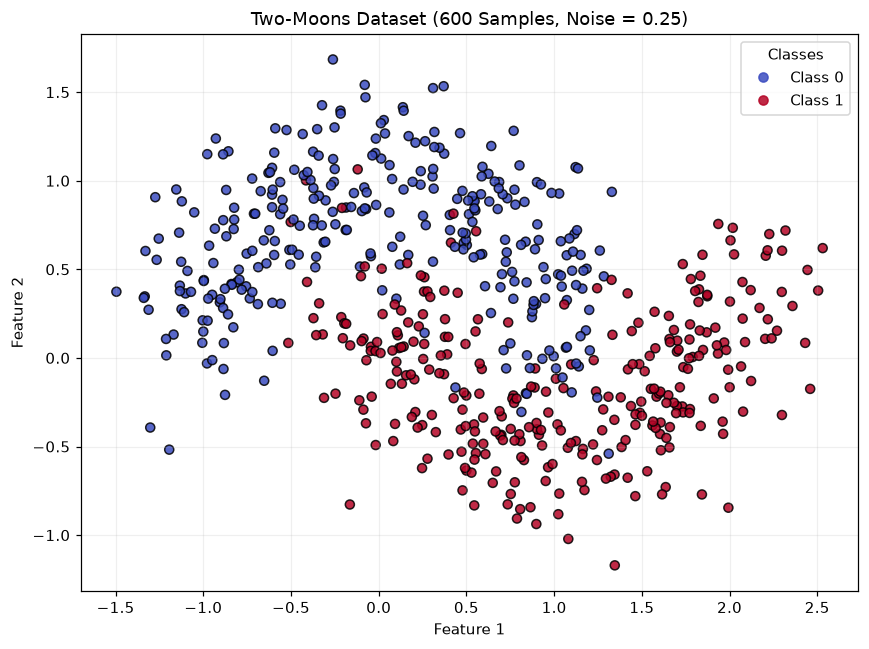

In [41]:
plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    X[:, 0], X[:, 1],
    c=y, cmap="coolwarm", edgecolors="black", s=35, alpha=0.85,
)

plt.title("Two-Moons Dataset (600 Samples, Noise = 0.25)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend(
    handles=scatter.legend_elements()[0],
    labels=["Class 0", "Class 1"],
    title="Classes",
)
plt.tight_layout()
plt.show()

In [42]:
df = pd.DataFrame(X, columns=["feature_1", "feature_2"])
df["class"] = y

print("Dataset shape:", df.shape)
print("\nClass counts:")
print(df["class"].value_counts().sort_index())
print("\nFeature summary (unscaled):")
print(df[["feature_1", "feature_2"]].describe().loc[["mean", "std", "min", "max"]])

# Spread ratio tells us how much the scaler will have to correct.
ratio = df["feature_1"].std() / df["feature_2"].std()
print(f"\nStd ratio feature_1 / feature_2 = {ratio:.2f} "
      "-> un-equal scales, so scaling is not optional here.")

df.head()

Dataset shape: (600, 3)

Class counts:
class
0    300
1    300
Name: count, dtype: int64

Feature summary (unscaled):
      feature_1  feature_2
mean   0.507060   0.273617
std    0.913021   0.563528
min   -1.495510  -1.170594
max    2.530857   1.684352

Std ratio feature_1 / feature_2 = 1.62 -> un-equal scales, so scaling is not optional here.


,feature_1,feature_2,class
0,0.625460,1.039122,0
1,0.698887,-0.434031,1
2,1.577001,0.054440,1
3,0.911745,0.665198,0
4,-0.313873,0.651696,0


Before modelling, it is worth seeing how the difficulty of the problem changes with noise.
The noise level sets the irreducible error, and later (§9) we measure how each kernel copes.

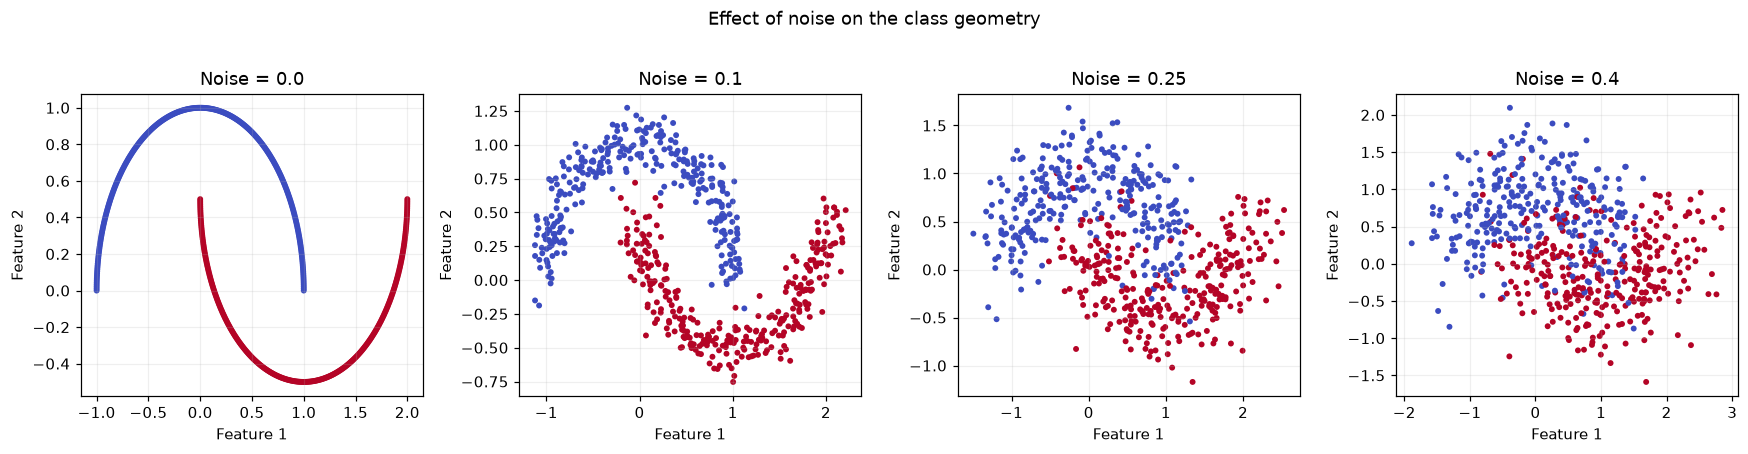

In [43]:
noise_levels = [0.0, 0.10, 0.25, 0.40]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for ax, noise in zip(axes, noise_levels):
    X_noise, y_noise = make_moons(
        n_samples=600, noise=noise, random_state=RANDOM_STATE
    )
    ax.scatter(
        X_noise[:, 0], X_noise[:, 1],
        c=y_noise, cmap="coolwarm", s=15, edgecolors="none",
    )
    ax.set_title(f"Noise = {noise}")
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")

plt.suptitle("Effect of noise on the class geometry", y=1.02)
plt.tight_layout()
plt.show()

## 3. Train / test split

80/20 with `stratify=y` so both parts keep the 50/50 class balance, and `random_state` fixed
for reproducibility. `X_test` is touched **exactly once**, at the very end (§10) every
comparison, every parameter choice and every plot before that uses only `X_train`.

In [44]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Training features:", X_train.shape)
print("Testing features: ", X_test.shape)
print("\nTraining class counts:")
print(pd.Series(y_train).value_counts().sort_index())
print("\nTesting class counts:")
print(pd.Series(y_test).value_counts().sort_index())

Training features: (480, 2)
Testing features:  (120, 2)

Training class counts:
0    240
1    240
Name: count, dtype: int64

Testing class counts:
0    60
1    60
Name: count, dtype: int64


In [45]:
assert X_train.shape == (480, 2)
assert X_test.shape == (120, 2)
assert len(y_train) == 480
assert len(y_test) == 120
assert set(np.unique(y_train)) == {0, 1}
print("All split checks passed.")

All split checks passed.


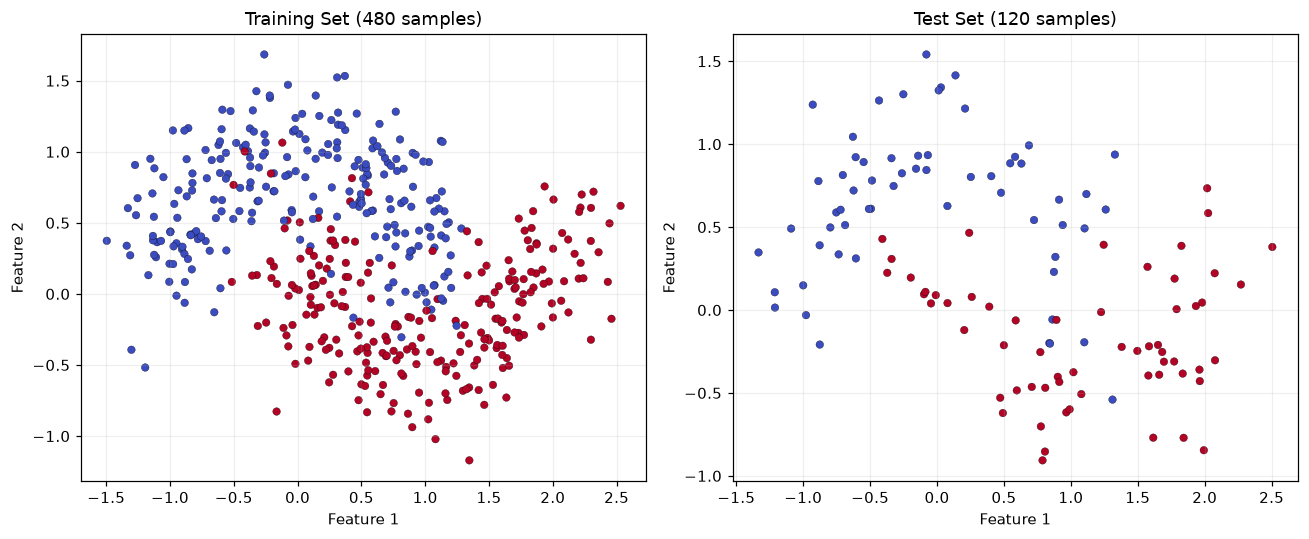

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, Xs, ys, title in [
    (axes[0], X_train, y_train, "Training Set (480 samples)"),
    (axes[1], X_test, y_test, "Test Set (120 samples)"),
]:
    ax.scatter(
        Xs[:, 0], Xs[:, 1],
        c=ys, cmap="coolwarm", s=25, edgecolors="black", linewidths=0.2,
    )
    ax.set_title(title)
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")

plt.tight_layout()
plt.show()

## 4. Feature scaling and data leakage

`StandardScaler` subtracts the mean and divides by the standard deviation, so both features end
up on the same footing. This matters for an SVM specifically: the kernel is a function of
*distances*, so a feature with a large spread would dominate the similarity computation and
swamp the `gamma` parameter.

**Leakage.** The scaler's mean and standard deviation are statistics of the data. If they were
computed on the full dataset including the test rows information about the test set would
leak into training and the held-out score would be optimistic. The fix used throughout this
notebook is to put the scaler *inside* the `Pipeline`: during cross-validation scikit-learn
re-fits the scaler on each training fold only and applies that same fold's statistics to the
validation fold.

In [47]:
# Before scaling: per-feature spread and location.
print("Before scaling:")
print(
    pd.DataFrame(X_train, columns=["feature_1", "feature_2"])
    .describe()
    .loc[["mean", "std", "min", "max"]]
)

scaler_demo = StandardScaler().fit(X_train)          # fit on TRAIN only
X_train_scaled = scaler_demo.transform(X_train)
X_test_scaled = scaler_demo.transform(X_test)

print("\nAfter scaling (train):")
print(
    pd.DataFrame(X_train_scaled, columns=["feature_1", "feature_2"])
    .describe()
    .loc[["mean", "std", "min", "max"]]
)

print("\nAfter scaling (test, transformed with the TRAIN statistics):")
print(
    pd.DataFrame(X_test_scaled, columns=["feature_1", "feature_2"])
    .describe()
    .loc[["mean", "std", "min", "max"]]
)

Before scaling:
      feature_1  feature_2
mean   0.503790   0.282070
std    0.901863   0.559758
min   -1.495510  -1.170594
max    2.530857   1.684352

After scaling (train):
         feature_1     feature_2
mean -3.552714e-16 -3.330669e-17
std   1.001043e+00  1.001043e+00
min  -2.219168e+00 -2.597873e+00
max   2.249988e+00  2.507772e+00

After scaling (test, transformed with the TRAIN statistics):
      feature_1  feature_2
mean   0.018148  -0.075584
std    1.065753   1.036374
min   -2.039830  -2.125432
max    2.221301   2.251230


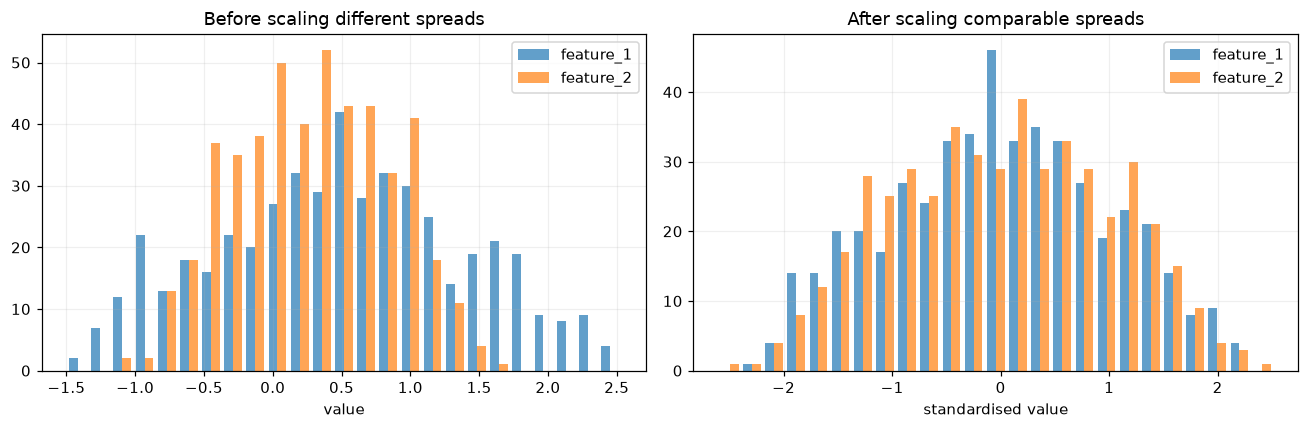

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(
    [X_train[:, 0], X_train[:, 1]],
    bins=25, label=["feature_1", "feature_2"], alpha=0.7,
)
axes[0].set_title("Before scaling different spreads")
axes[0].set_xlabel("value")
axes[0].legend()

axes[1].hist(
    [X_train_scaled[:, 0], X_train_scaled[:, 1]],
    bins=25, label=["feature_1", "feature_2"], alpha=0.7,
)
axes[1].set_title("After scaling comparable spreads")
axes[1].set_xlabel("standardised value")
axes[1].legend()

plt.tight_layout()
plt.show()

## 5. Baseline model and the cross-validation harness

A single 80/20 split gives one number with no sense of its variability, so parameter selection
below uses **5-fold stratified cross-validation on `X_train`**. Stratified folds keep the class
ratio intact in every fold, which matters because a fold that happened to be class-imbalanced
would distort balanced accuracy.

Scoring is `balanced_accuracy` the average of per-class recall. On this balanced dataset it
sits very close to plain accuracy, but it stays honest if the classes were ever uneven.

In [49]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

baseline_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC(kernel="linear", C=1.0)),
])

cv_scores = cross_val_score(
    baseline_svm, X_train, y_train, cv=cv, scoring="balanced_accuracy"
)

print("Balanced accuracy for each fold:", np.round(cv_scores, 4))
print(f"\nMean balanced accuracy: {cv_scores.mean():.4f}")
print(f"Standard deviation:     {cv_scores.std():.4f}")

Balanced accuracy for each fold: [0.8958 0.8646 0.8646 0.875  0.8229]

Mean balanced accuracy: 0.8646
Standard deviation:     0.0238


## 6. Hyperparameter search

Three models on the same split and the same folds:

| Kernel | Grid | Candidates |
|---|---|---|
| Linear | `C` | 4 |
| Polynomial | `C` × `degree` × `gamma` | 4 × 2 × 3 = 24 |
| RBF | `C` × `gamma` | 4 × 4 = 16 |

`C` is the penalty for margin violations in every kernel: **small `C`** accepts more violations
in exchange for a wider, softer margin (more bias, less variance); **large `C`** pushes for a
hard margin and can overfit. `gamma` is RBF-specific (the reach of a single training point) and
`degree` is polynomial-specific. Both are examined again in §7.

In [50]:
linear_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC(kernel="linear")),
])
linear_grid = {"svc__C": [0.1, 1, 10, 100]}

poly_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC(kernel="poly", coef0=1)),
])
poly_grid = {
    "svc__C": [0.1, 1, 10, 100],
    "svc__degree": [2, 3],
    "svc__gamma": ["scale", 0.1, 1],
}

rbf_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC(kernel="rbf")),
])
rbf_grid = {
    "svc__C": [0.1, 1, 10, 100],
    "svc__gamma": [0.01, 0.1, 1, 10],
}

In [51]:
searches = {
    "Linear": GridSearchCV(
        linear_pipeline, linear_grid,
        scoring="balanced_accuracy", cv=cv, n_jobs=-1,
    ),
    "Polynomial": GridSearchCV(
        poly_pipeline, poly_grid,
        scoring="balanced_accuracy", cv=cv, n_jobs=-1,
    ),
    "RBF": GridSearchCV(
        rbf_pipeline, rbf_grid,
        scoring="balanced_accuracy", cv=cv, n_jobs=-1,
    ),
}

for name, search in searches.items():
    search.fit(X_train, y_train)
    print(f"{name:>10} | best CV balanced accuracy = {search.best_score_:.4f} "
          f"(+/- {search.cv_results_['std_test_score'][search.best_index_]:.4f}) "
          f"| {search.best_params_}")

    Linear | best CV balanced accuracy = 0.8646 (+/- 0.0238) | {'svc__C': 1}
Polynomial | best CV balanced accuracy = 0.9458 (+/- 0.0167) | {'svc__C': 10, 'svc__degree': 3, 'svc__gamma': 1}
       RBF | best CV balanced accuracy = 0.9500 (+/- 0.0153) | {'svc__C': 10, 'svc__gamma': 1}


In [52]:
results = (
    pd.DataFrame([
        {
            "Kernel": name,
            "Best CV Balanced Accuracy": search.best_score_,
            "CV Std (best params)": search.cv_results_["std_test_score"][search.best_index_],
            "Best Parameters": search.best_params_,
        }
        for name, search in searches.items()
    ])
    .sort_values("Best CV Balanced Accuracy", ascending=False)
    .reset_index(drop=True)
)

results["CV Std (best params)"] = results["CV Std (best params)"].round(4)
results

,Kernel,Best CV Balanced Accuracy,CV Std (best params),Best Parameters
0,RBF,0.950000,0.0153,"{'svc__C': 10, 'svc__gamma': 1}"
1,Polynomial,0.945833,0.0167,"{'svc__C': 10, 'svc__degree': 3, 'svc__gamma': 1}"
2,Linear,0.864583,0.0238,{'svc__C': 1}


### Reading the grid search

* The **linear kernel stops at ≈0.865**. That ceiling is the whole point of the exercise: the
  moons are interleaved, and no straight line separates them, so no amount of tuning `C` helps.
* Both nonlinear kernels reach **≈0.95** a jump of about **8.5 points** over the baseline.
* RBF (0.9500) and polynomial (0.9458) differ by **0.4 points**. That is roughly **two
  training points**, against a fold-to-fold standard deviation of about **0.024** five times
  larger. **The two are statistically indistinguishable on this data**, and the notebook does
  not treat one as the winner on score alone. §10 picks between them on other grounds.
* The best `C` for both nonlinear kernels is 10, not 100. Selection stopped at the plateau
  before the grid edge rather than at it, which is what you want to see: an optimum sitting on
  the boundary of the grid usually means the grid should have been wider.

The `C` sensitivity is worth a direct look, since "why C=10" is a natural question.

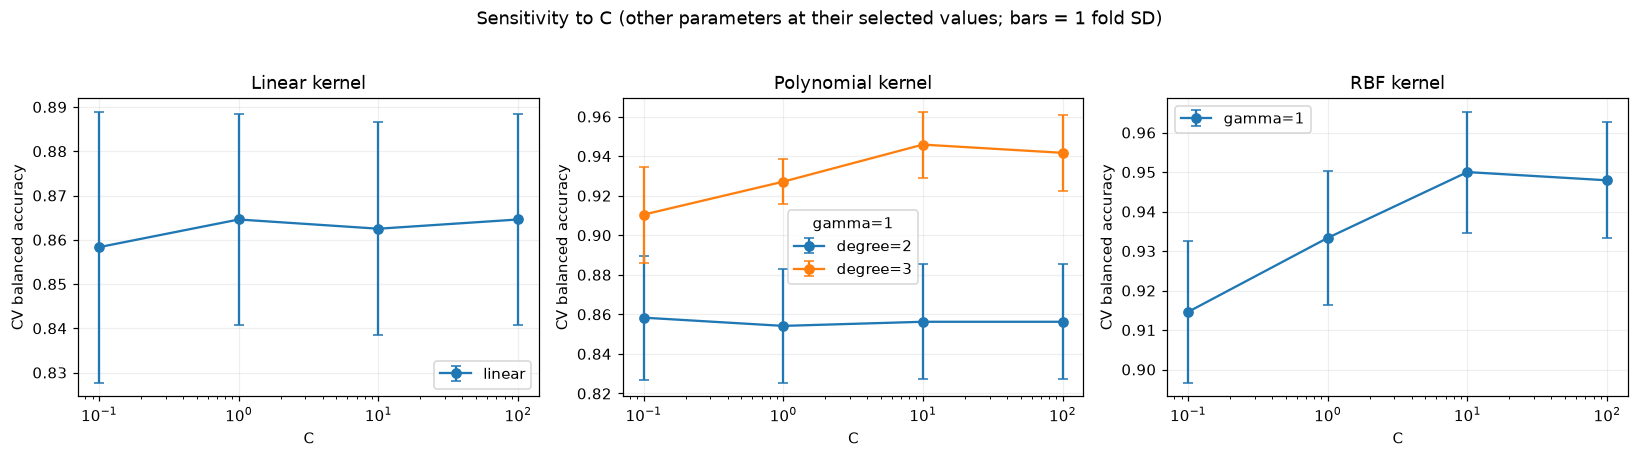

In [53]:
# How sensitive is each kernel to C? Plot the CV curve for the *other* parameters fixed
# at their best values (for polynomials, at each degree).
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, search) in zip(axes, searches.items()):
    res = pd.DataFrame(search.cv_results_)
    cvals = sorted(res["param_svc__C"].unique(), key=lambda v: float(v))

    if name == "Polynomial":
        best_deg = search.best_params_["svc__degree"]
        best_gam = search.best_params_["svc__gamma"]
        for deg in sorted(res["param_svc__degree"].unique()):
            sub = res[
                (res["param_svc__degree"] == deg)
                & (res["param_svc__gamma"] == best_gam)
            ].sort_values("param_svc__C", key=lambda s: s.astype(float))
            ax.errorbar(sub["param_svc__C"].astype(float), sub["mean_test_score"],
                        yerr=sub["std_test_score"], marker="o", capsize=3,
                        label=f"degree={deg}")
        ax.legend(title=f"gamma={best_gam}")
    else:
        m = res["mean_test_score"]
        s = res["std_test_score"]
        # Best curve if a second parameter exists, else the single curve.
        if name == "RBF":
            best_gam = search.best_params_["svc__gamma"]
            mask = res["param_svc__gamma"] == best_gam
            m = m[mask]; s = s[mask]
            cvals = res.loc[mask, "param_svc__C"].astype(float)
            label = f"gamma={best_gam}"
        else:
            cvals = res["param_svc__C"].astype(float)
            label = "linear"
        ax.errorbar(cvals, m, yerr=s, marker="o", capsize=3, label=label)
        ax.legend()

    ax.set_xscale("log")
    ax.set_xlabel("C")
    ax.set_ylabel("CV balanced accuracy")
    ax.set_title(f"{name} kernel")

plt.suptitle("Sensitivity to C (other parameters at their selected values; bars = 1 fold SD)",
             y=1.03)
plt.tight_layout()
plt.show()

## 7. Kernel study polynomial vs RBF

The kernel trick computes a similarity $K(x, x')$ in a high-dimensional feature space without
ever forming the coordinates of that space. Two kernels are in play:

**Polynomial** $K(x,x') = (\gamma\, x^\top x' + r)^d$ the feature space consists of all
monomials up to degree $d$. Degree 2 captures pairwise interaction terms, so the boundary is a
conic section; degree 3 adds cubic terms and bends further.

**RBF (Gaussian)** $K(x,x') = \exp(-\gamma \lVert x - x' \rVert^2)$ an *infinite-dimensional*
feature space, locally weighted: a point's influence decays with distance at a scale set by
$\gamma$.

In [54]:

import sys
for _cand in [Path.cwd() / "src", Path.cwd().parent / "src"]:
    if (_cand / "svm_utils.py").exists():
        sys.path.insert(0, str(_cand))
        break
else:
    raise FileNotFoundError("could not locate src/svm_utils.py from " + str(Path.cwd()))

from svm_utils import (
    plot_decision_boundary,
    median_pairwise_distance,
    suggested_gamma,
)

plot_boundary = plot_decision_boundary   # shorter alias for use in the panels below
print("helpers imported from", _cand.relative_to(_cand.parent))

helpers imported from src


### 7.1 Decision boundaries with margins

The dashed lines are the margin edges, where the decision function equals ±1. Black rings mark the **support vectors**: the training points that lie *on or inside* the margin
(or on its wrong side with a finite `C` the margin is soft). Only these points determine the
boundary. The solid line is the decision boundary (decision function = 0).

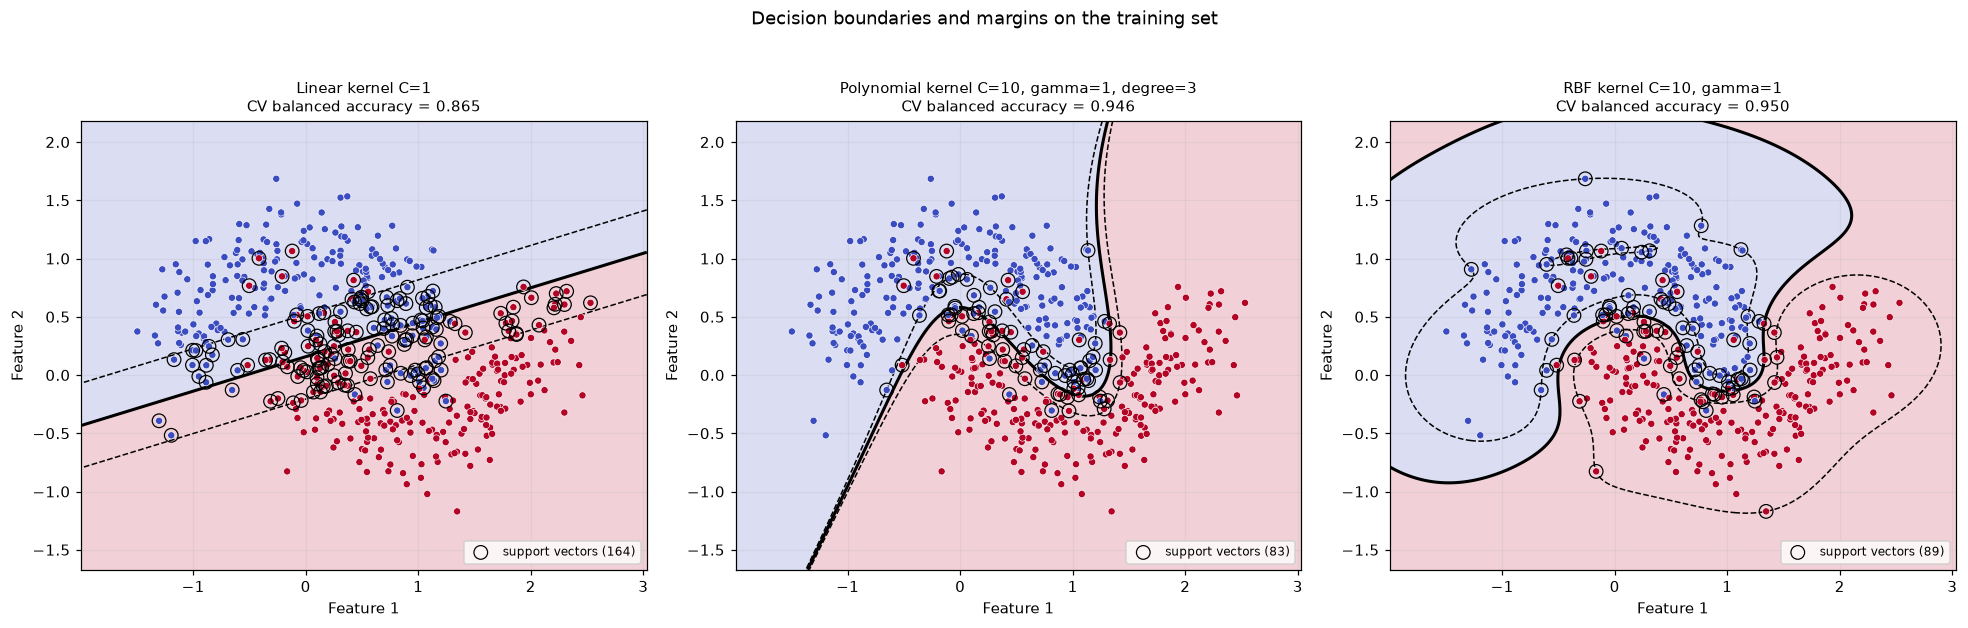

In [55]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

for ax, (name, search) in zip(axes, searches.items()):
    model = search.best_estimator_
    svc = model.named_steps["svc"]
    params = search.best_params_
    desc = f"C={params['svc__C']}"
    if "svc__gamma" in params:
        desc += f", gamma={params['svc__gamma']}"
    if "svc__degree" in params:
        desc += f", degree={params['svc__degree']}"
    plot_boundary(
        model, X_train, y_train,
        f"{name} kernel {desc}\nCV balanced accuracy = {search.best_score_:.3f}",
        ax=ax,
    )

plt.suptitle("Decision boundaries and margins on the training set", y=1.03)
plt.tight_layout()
plt.show()

The three pictures tell the story directly:

* **Linear** puts down one straight boundary and cannot follow the crescents its error is
  structural, not tuning.
* **Polynomial (degree 3)** bends into a smooth curve that follows the interlocking shape.
* **RBF (gamma=1)** is locally flexible: it traces the crescents closely and needs about as many support
  vectors as the polynomial model (89 vs 83), against 164 for the linear model.

### 7.2 The effect of `degree`

Degree 1 of a polynomial kernel *is* the linear kernel, so the sequence 1 → 2 → 3 → 5 shows the
progression from underfitting to fitting to overfitting. Each panel is tuned separately, so a
degree only loses if it cannot reach the same accuracy even with its best `C` and `gamma`.

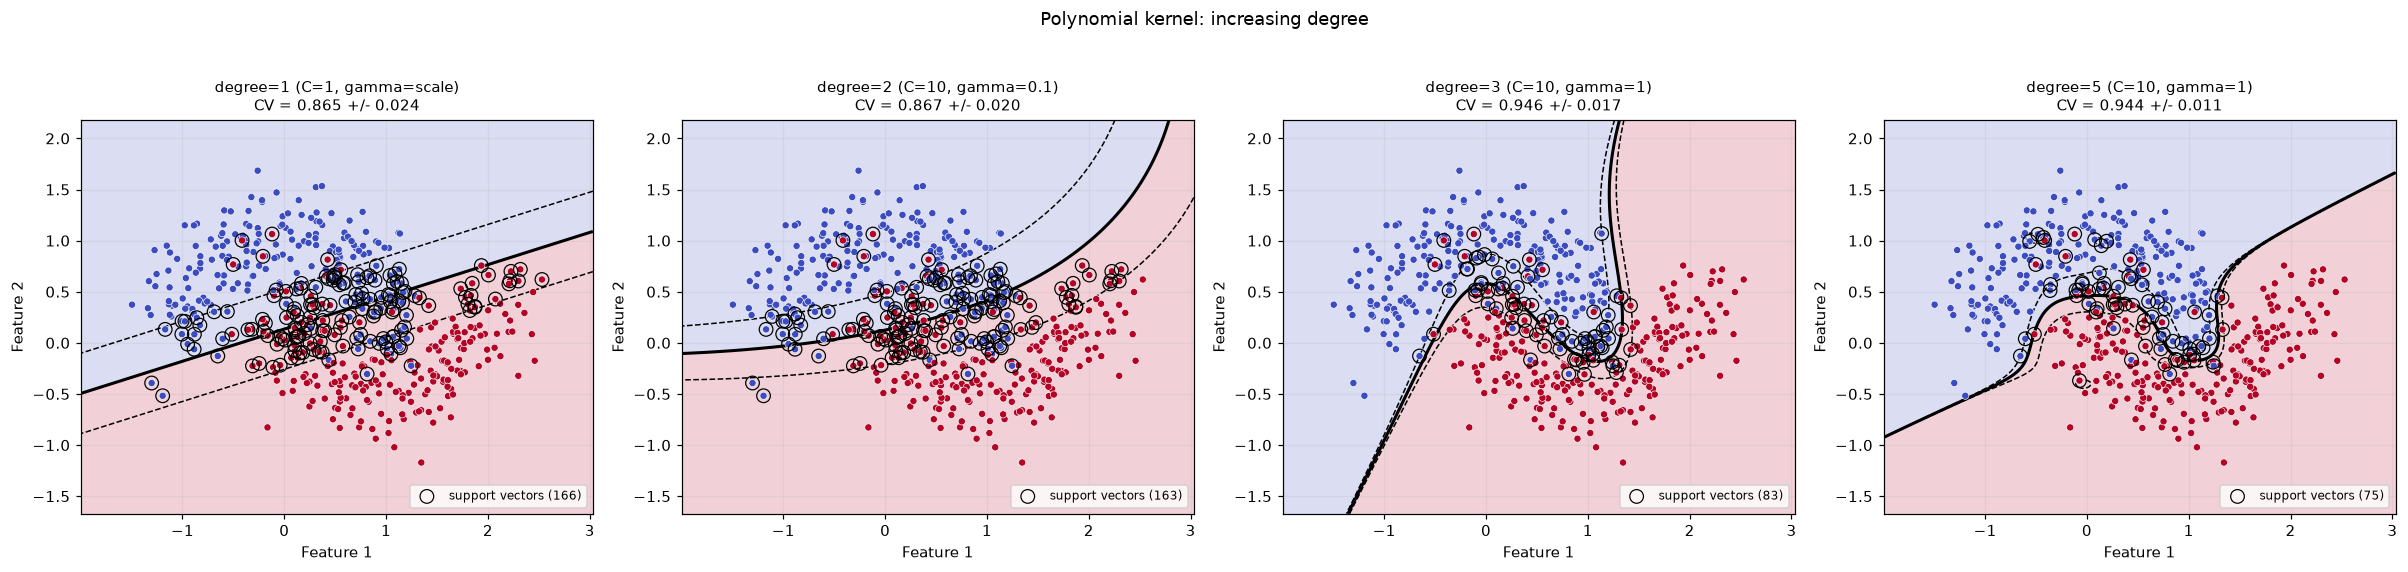

CV balanced accuracy by degree
  degree 1: 0.8646 (+/- 0.0238)   n_SV=166   {'svc__C': 1, 'svc__gamma': 'scale'}
  degree 2: 0.8667 (+/- 0.0202)   n_SV=163   {'svc__C': 10, 'svc__gamma': 0.1}
  degree 3: 0.9458 (+/- 0.0167)   n_SV= 83   {'svc__C': 10, 'svc__gamma': 1}
  degree 5: 0.9437 (+/- 0.0106)   n_SV= 75   {'svc__C': 10, 'svc__gamma': 1}


In [56]:
degrees = [1, 2, 3, 5]
deg_models = {}
deg_scores = {}

for d in degrees:
    pipe = Pipeline([("scaler", StandardScaler()),
                     ("svc", SVC(kernel="poly", degree=d, coef0=1))])
    gs = GridSearchCV(
        pipe,
        {"svc__C": [0.1, 1, 10, 100],
         "svc__gamma": ["scale", 0.1, 1]},
        scoring="balanced_accuracy", cv=cv, n_jobs=-1,
    )
    gs.fit(X_train, y_train)
    deg_models[d] = gs.best_estimator_
    deg_scores[d] = (gs.best_score_,
                     gs.cv_results_["std_test_score"][gs.best_index_],
                     gs.best_params_)

fig, axes = plt.subplots(1, 4, figsize=(22, 5))
for ax, d in zip(axes, degrees):
    score, sd, params = deg_scores[d]
    plot_boundary(deg_models[d], X_train, y_train,
                  f"degree={d} (C={params['svc__C']}, gamma={params['svc__gamma']})\n"
                  f"CV = {score:.3f} +/- {sd:.3f}",
                  ax=ax)
plt.suptitle("Polynomial kernel: increasing degree", y=1.03)
plt.tight_layout()
plt.show()

print("CV balanced accuracy by degree")
for d in degrees:
    score, sd, params = deg_scores[d]
    n_sv = len(deg_models[d].named_steps["svc"].support_)
    print(f"  degree {d}: {score:.4f} (+/- {sd:.4f})   n_SV={n_sv:>3}   {params}")

Degree 1 lands at the linear baseline (0.8646), confirming the algebra: a degree-1 polynomial
kernel *is* a linear kernel. Degree 2 adds almost nothing (0.8667): its boundary is a conic, which
cannot wrap round two interlocking crescents. Degree 3 is where the gain appears (0.9458), and
degree 5 does not improve on it (0.9437, within one fold SD).

The support-vector count tells the same story: 166 → 163 → 83 → 75 for degrees 1, 2, 3, 5. Once
the feature space can represent the shape, far fewer points are needed to define the boundary.

### 7.3 The effect of `gamma` (RBF)

`gamma` sets the reach of a single training point. Small `gamma` means a broad, slowly-varying
influence and an almost linear boundary; large `gamma` means a narrow spike, so the boundary
breaks into islands around individual points. This is the single most important parameter to
get right, and it is why the scaled features from §4 matter `gamma` is measured in units of
the feature space.

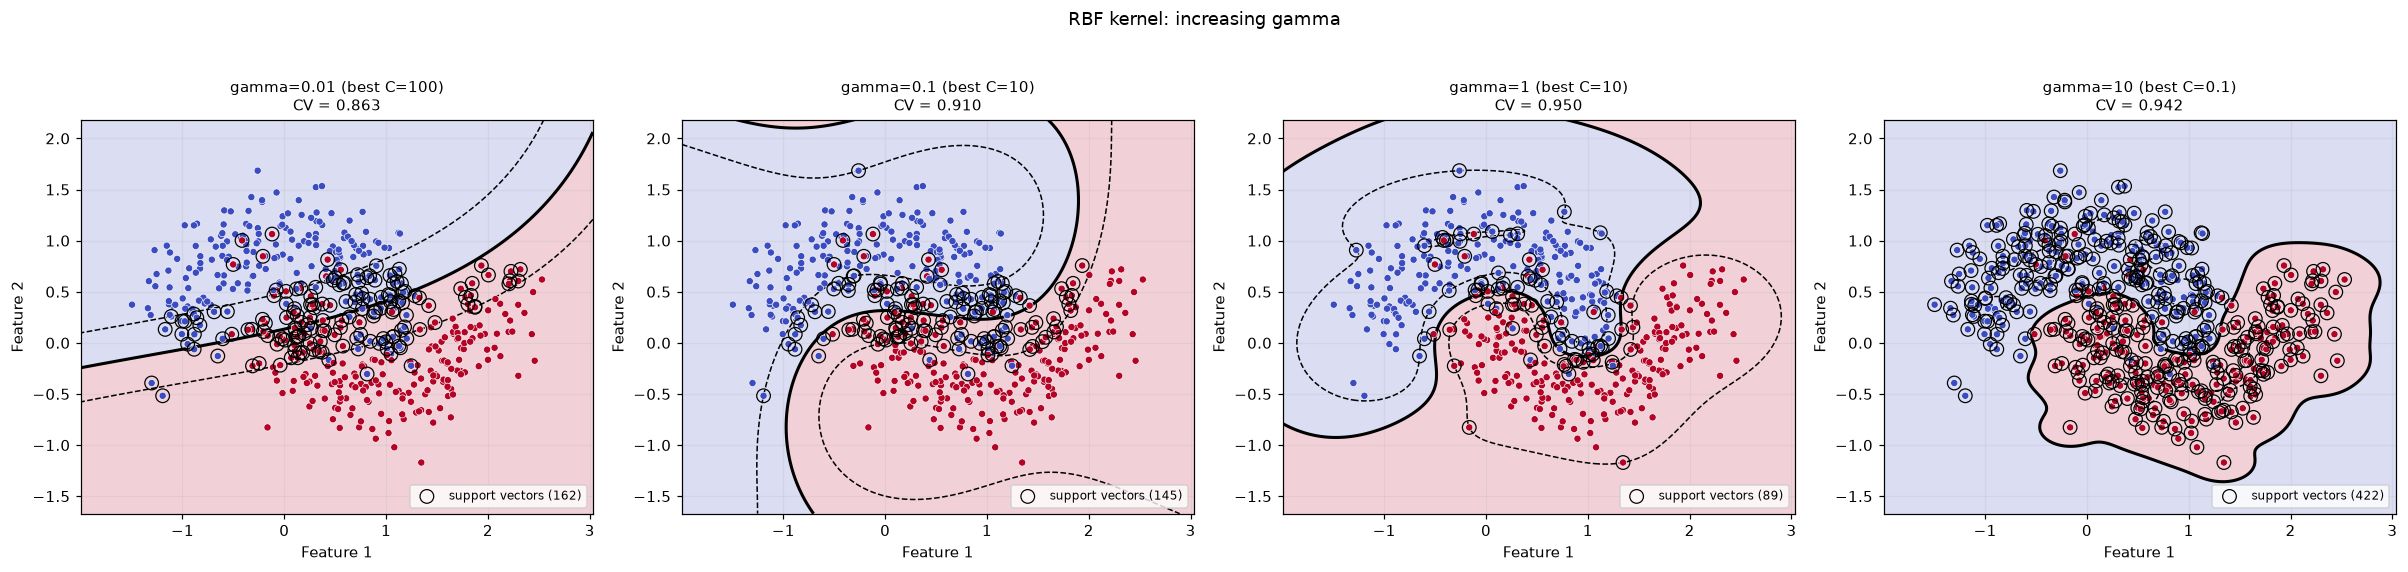

CV balanced accuracy by gamma (C tuned per gamma)
  gamma  0.01: 0.8625 (+/- 0.0275)   best C=100
  gamma   0.1: 0.9104 (+/- 0.0268)   best C=10
  gamma     1: 0.9500 (+/- 0.0153)   best C=10
  gamma    10: 0.9417 (+/- 0.0169)   best C=0.1


In [57]:
gammas = [0.01, 0.1, 1, 10]

fig, axes = plt.subplots(1, 4, figsize=(22, 5))
gamma_scores = {}

for ax, g in zip(axes, gammas):
    pipe = Pipeline([("scaler", StandardScaler()),
                     ("svc", SVC(kernel="rbf"))])
    gs = GridSearchCV(
        pipe, {"svc__C": [0.1, 1, 10, 100], "svc__gamma": [g]},
        scoring="balanced_accuracy", cv=cv, n_jobs=-1,
    )
    gs.fit(X_train, y_train)
    gamma_scores[g] = (gs.best_score_,
                       gs.cv_results_["std_test_score"][gs.best_index_],
                       gs.best_params_["svc__C"])
    plot_boundary(gs.best_estimator_, X_train, y_train,
                  f"gamma={g} (best C={gs.best_params_['svc__C']})\n"
                  f"CV = {gs.best_score_:.3f}",
                  ax=ax)

plt.suptitle("RBF kernel: increasing gamma", y=1.03)
plt.tight_layout()
plt.show()

print("CV balanced accuracy by gamma (C tuned per gamma)")
for g in gammas:
    score, sd, best_c = gamma_scores[g]
    print(f"  gamma {g:>5}: {score:.4f} (+/- {sd:.4f})   best C={best_c}")

Left to right: `gamma=0.01` is too smooth the boundary is almost straight and cannot bend into
the crescents (underfitting, CV 0.863). `gamma=1` traces them well (0.950). `gamma=10` gives a
more wiggly boundary that starts to wrap individual noisy points; its CV score (0.942) is within
one fold SD of `gamma=1`, so CV alone cannot separate the two, but the boundary shape shows the
direction of overfitting and note that it needed a much smaller `C` (0.1) to stay competitive.

In [58]:
# The heuristic belongs on the *scaled* data, because that is what the kernel sees.
gamma_median = median_pairwise_distance(StandardScaler().fit_transform(X_train))
print(f"median pairwise distance of scaled training data: {gamma_median:.3f}")
print(f"rule of thumb 1 / median                    = {1 / gamma_median:.3f}")
print(f"rule of thumb 1 / (2 * median^2)            = {1 / (2 * gamma_median ** 2):.3f}")
print(f"rule of thumb via src.suggested_gamma()     = "
      f"{suggested_gamma(StandardScaler().fit_transform(X_train)):.3f}")
print(f"\nselected gamma from the grid search          = "
      f"{searches['RBF'].best_params_['svc__gamma']}")

median pairwise distance of scaled training data: 1.723
rule of thumb 1 / median                    = 0.580
rule of thumb 1 / (2 * median^2)            = 0.168
rule of thumb via src.suggested_gamma()     = 0.580

selected gamma from the grid search          = 1


The median pairwise distance of the scaled data is about **1.7**, so the classes sit roughly one
to two units apart in the standardised space. That puts the natural length scale at order 1,
which is consistent with the grid search choosing **`gamma=1`** rather than the value the raw
`1/(2·median²) ≈ 0.17` recipe suggests. That recipe is a sensible starting point for data whose
geometry has not already been normalised to unit spread; here the `StandardScaler` has done that
work, so `gamma=1` means "a point's influence reaches roughly its own neighbours".

This is a **sanity check on the selected value, not a replacement for cross-validation**. The
grid search is what actually selected it it preferred `gamma=1` over `0.1`, `0.01` and `10`
and §7.3 shows the score surface behind that choice. The heuristic is what you would try first if
the grid search had not been run.

## 8. Support vectors

Only the points on or inside the margin determine the boundary the rest could be deleted and
the fitted model would not change. Their count is also a rough complexity read-out: more
support vectors means the boundary depends on more of the data.

In [59]:
rows = []
for name, search in searches.items():
    svc = search.best_estimator_.named_steps["svc"]
    rows.append({
        "Kernel": name,
        "Support vectors": len(svc.support_vectors_),
        "Share of training set": len(svc.support_vectors_) / len(X_train),
        "Class 0": int(svc.n_support_[0]),
        "Class 1": int(svc.n_support_[1]),
        "CV balanced accuracy": search.best_score_,
    })

sv_df = pd.DataFrame(rows).sort_values("Support vectors").reset_index(drop=True)
sv_df["Share of training set"] = (sv_df["Share of training set"] * 100).round(1).astype(str) + "%"
sv_df["CV balanced accuracy"] = sv_df["CV balanced accuracy"].round(4)
sv_df

,Kernel,Support vectors,Share of training set,Class 0,Class 1,CV balanced accuracy
0,Polynomial,83,17.3%,42,41,0.9458
1,RBF,89,18.5%,48,41,0.9500
2,Linear,164,34.2%,82,82,0.8646


The linear model needs **164 support vectors (34% of the training set)** and still underfits
it is holding on to a third of the data and cannot separate the classes. Both nonlinear kernels
use far fewer (83 and 89, ≈18%) for a much better fit. Fewer support vectors for more accuracy
is the kernel trick paying off.

## 9. Error analysis robustness to noise

The parameter choices were made at `noise=0.25`. A model that is genuinely capturing the
structure should degrade gracefully as that noise grows; a model that has memorised its training
set should fall apart sooner. Averaging over several random draws separates the effect of noise
from the effect of one unlucky sample.

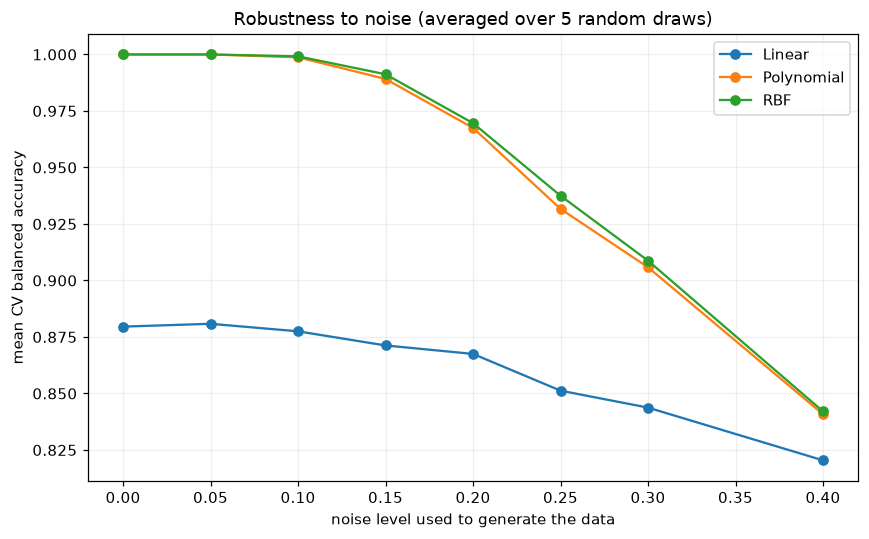

,Linear,Polynomial,RBF
noise=0.0,0.880,1.000,1.000
noise=0.05,0.881,1.000,1.000
noise=0.1,0.878,0.999,0.999
noise=0.15,0.871,0.989,0.991
noise=0.2,0.868,0.968,0.970
noise=0.25,0.851,0.932,0.938
noise=0.3,0.844,0.906,0.909
noise=0.4,0.820,0.841,0.842


In [60]:
noise_curve = [0.00, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40]
seeds = [0, 1, 2, 3, 4]

robustness = {k: [] for k in ["Linear", "Polynomial", "RBF"]}

for noise in noise_curve:
    fold_means = {k: [] for k in robustness}
    for seed in seeds:
        Xn, yn = make_moons(n_samples=600, noise=noise, random_state=seed)
        Xn_tr, _, yn_tr, _ = train_test_split(
            Xn, yn, test_size=0.20, random_state=seed, stratify=yn
        )
        for name, search in searches.items():
            fresh = search.best_estimator_          # unfitted clone
            s = cross_val_score(fresh, Xn_tr, yn_tr,
                                cv=cv, scoring="balanced_accuracy")
            fold_means[name].append(s.mean())
    for k in robustness:
        robustness[k].append(np.mean(fold_means[k]))

plt.figure(figsize=(8, 5))
for k, vals in robustness.items():
    plt.plot(noise_curve, vals, marker="o", label=k)
plt.xlabel("noise level used to generate the data")
plt.ylabel("mean CV balanced accuracy")
plt.title("Robustness to noise (averaged over 5 random draws)")
plt.legend()
plt.tight_layout()
plt.show()

pd.DataFrame(robustness, index=[f"noise={n}" for n in noise_curve]).round(3)

At zero noise the linear model already trails badly, and the two nonlinear models nearly saturate.
As noise grows the gap narrows not because linear improves, but because the ceiling drops:
above roughly 0.30 the Gaussian scatter makes the two crescents genuinely overlap, so there is
less structure left for any model to exploit. The nonlinear models stay ahead throughout, which
is the expected shape.

## 10. Model selection and final test-set evaluation

### The choice

RBF (0.9500) and polynomial degree 3 (0.9458) are **tied within noise** the difference is
about two training points against a fold standard deviation five times larger. Selecting between
them therefore rests on reasoning, not on the third decimal place:

| | RBF | Polynomial (degree 3) |
|---|---|---|
| Parameters to justify | `C`, `gamma` | `C`, `gamma`, `degree` |
| Boundary smoothness | Very smooth at `gamma=1` | Smooth |
| Support vectors | 89 | 83 |
| Risk as data grows | Bounded (local kernel) | Degree-3 terms can extrapolate badly |
| Introspectability | Similarity to reference points | Explicit interaction terms |

**Selected: RBF with `C=10`, `gamma=1`.** The two score the same here; RBF is chosen because it
has one fewer structural assumption (no fixed polynomial degree to pick), its boundary is smooth
and dictated by a single interpretable length scale, and it is the kernel that degrades most
predictably when the data changes the polynomial model's degree-3 extrapolation is a liability
outside the region where the data lives.

### The test set

`X_test` has been untouched until now. It is used once, here.

In [61]:
summary = []
for name, search in searches.items():
    model = search.best_estimator_
    pred = model.predict(X_test)
    p = search.best_params_
    desc = f"C={p['svc__C']}"
    if "svc__gamma" in p:
        desc += f", gamma={p['svc__gamma']}"
    if "svc__degree" in p:
        desc += f", degree={p['svc__degree']}"
    summary.append({
        "Kernel": name,
        "Parameters": desc,
        "CV Balanced Acc": round(search.best_score_, 4),
        "Test Accuracy": round(accuracy_score(y_test, pred), 4),
        "Test Balanced Acc": round(balanced_accuracy_score(y_test, pred), 4),
        "Test F1": round(f1_score(y_test, pred), 4),
    })

summary_df = pd.DataFrame(summary).sort_values(
    "Test Balanced Acc", ascending=False
).reset_index(drop=True)

# Selection uses CV score + the reasoning in the table above; the test set plays no part.
best_name = "RBF"
assert best_name == max(searches.items(), key=lambda kv: kv[1].best_score_)[0]
summary_df

,Kernel,Parameters,CV Balanced Acc,Test Accuracy,Test Balanced Acc,Test F1
0,RBF,"C=10, gamma=1",0.9500,0.9333,0.9333,0.9333
1,Polynomial,"C=10, gamma=1, degree=3",0.9458,0.9250,0.9250,0.9256
2,Linear,C=1,0.8646,0.8917,0.8917,0.8943


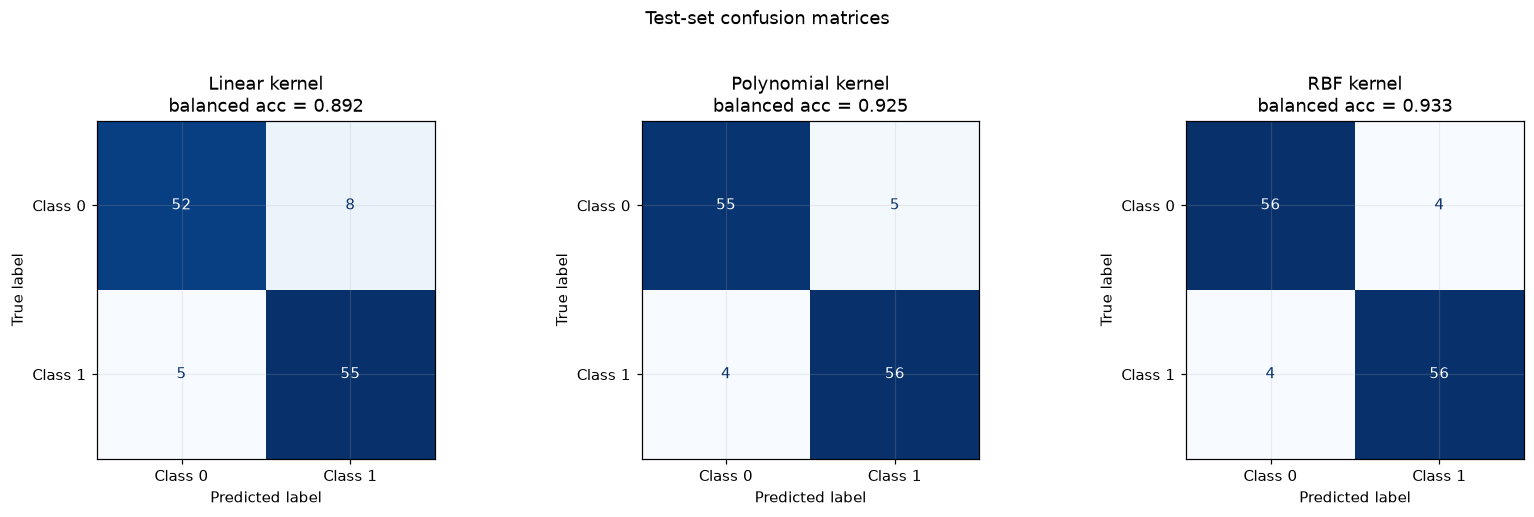

In [62]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, (name, search) in zip(axes, searches.items()):
    pred = search.best_estimator_.predict(X_test)
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred,
        display_labels=["Class 0", "Class 1"],
        cmap="Blues", ax=ax, colorbar=False,
    )
    ax.set_title(f"{name} kernel\nbalanced acc = "
                 f"{balanced_accuracy_score(y_test, pred):.3f}")

plt.suptitle("Test-set confusion matrices", y=1.03)
plt.tight_layout()
plt.show()

In [63]:
final_model = searches[best_name].best_estimator_
y_pred = final_model.predict(X_test)

print(f"Selected kernel: {best_name}")
print(f"Parameters:      {searches[best_name].best_params_}")
print(f"\nTest accuracy:          {accuracy_score(y_test, y_pred):.4f}")
print(f"Test balanced accuracy: {balanced_accuracy_score(y_test, y_pred):.4f}")
print(f"Test F1 score:          {f1_score(y_test, y_pred):.4f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0, digits=3))
print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))

Selected kernel: RBF
Parameters:      {'svc__C': 10, 'svc__gamma': 1}

Test accuracy:          0.9333
Test balanced accuracy: 0.9333
Test F1 score:          0.9333

Classification report:
              precision    recall  f1-score   support

           0      0.933     0.933     0.933        60
           1      0.933     0.933     0.933        60

    accuracy                          0.933       120
   macro avg      0.933     0.933     0.933       120
weighted avg      0.933     0.933     0.933       120

Confusion matrix:
[[56  4]
 [ 4 56]]


The held-out scores of the two nonlinear kernels land about 2 points below their cross-validated
scores (0.933 vs 0.950 and 0.925 vs 0.946) within the fold-to-fold SD of about 0.015–0.017, so
the CV harness was not badly biased. The linear model's test score (0.8917) is about
**2.7 points above** its CV score (0.8646) a reminder that a single 120-row test set carries
its own sampling noise, and that the CV estimate is the more trustworthy of the two. Its test
score still sits well below both nonlinear kernels, so the ceiling is a property of the problem,
not of the evaluation. The selected RBF model misclassifies 4 of 120 test points, symmetrically
(56/4 and 4/56), which is the expected residue of `noise=0.25` rather than a class-specific
failure.

## 11. Kernel Trick study

### 11.1 The principle

A linear SVM separates data using only **inner products** $x_i^\top x_j$ between training points.
Replace that inner product with a kernel $K(x_i, x_j)$ and you get the same algorithm operating
in a different space one whose coordinates are never written down.

The polynomial kernel $K(x,x') = (\gamma\, x^\top x' + r)^d$ **is** the inner product of the
degree-$d$ monomial feature map:

$$K(x, x') = \phi(x)^\top \phi(x')$$

for $\phi$ containing all monomials up to degree $d$. So an SVM trained with `kernel="poly"`
is exactly an SVM trained on $\phi(x)$ but the kernel version computes the result using only
$n^2$ kernel evaluations, while the explicit version must build and store the $O(n \cdot D)$
feature matrix, where $D$ grows combinatorially with $d$.

The RBF kernel goes further: its feature space is **infinite-dimensional**, so there is no
finite $\phi$ to materialise at all. The kernel trick is not an optimisation here it is the
only way to work in that space.

The next two cells make this concrete: first that the two computations agree, then what they
cost.

In [64]:
# --- Kernel trick, step 1: the kernel value IS an inner product in feature space ---
# For 2 inputs, degree 2, gamma=1, coef0=1:   K(x,z) = (x.z + 1)^2 = phi(x).phi(z)
# with the explicit 6-dimensional map  phi(x) = [1, sqrt2*x1, sqrt2*x2, x1^2, x2^2, sqrt2*x1*x2].
from sklearn.metrics.pairwise import polynomial_kernel

def phi(A):
    x1, x2 = A[:, 0], A[:, 1]
    return np.c_[np.ones(len(A)), np.sqrt(2) * x1, np.sqrt(2) * x2,
                 x1 ** 2, x2 ** 2, np.sqrt(2) * x1 * x2]

Xs = StandardScaler().fit(X_train).transform(X_train)       # scaler fitted on TRAIN only
K_kernel = polynomial_kernel(Xs, Xs, degree=2, gamma=1, coef0=1)   # n x n, no phi built
K_explicit = phi(Xs) @ phi(Xs).T                                   # n x 6 map, then inner products
print("phi(x) has", phi(Xs).shape[1], "dimensions; kernel matrix shape", K_kernel.shape)
print("max |K_kernel - phi.phi^T| =", np.abs(K_kernel - K_explicit).max())

# --- step 2: so an SVM on phi(x) and an SVM with the kernel are the same model ---
explicit = SVC(kernel="linear", C=10).fit(phi(Xs), y_train)
kernelised = SVC(kernel="poly", degree=2, coef0=1, gamma=1, C=10).fit(Xs, y_train)

df_e = explicit.decision_function(phi(Xs))
df_k = kernelised.decision_function(Xs)
print(f"\npredictions that disagree: {(explicit.predict(phi(Xs)) != kernelised.predict(Xs)).sum()} / {len(Xs)}")
print(f"max |decision_function difference| = {np.abs(df_e - df_k).max():.2e}")
print(f"training accuracy  explicit: {explicit.score(phi(Xs), y_train):.4f}   "
      f"kernel: {kernelised.score(Xs, y_train):.4f}")


phi(x) has 6 dimensions; kernel matrix shape (480, 480)
max |K_kernel - phi.phi^T| = 1.4210854715202004e-14

predictions that disagree: 0 / 480
max |decision_function difference| = 3.14e-12
training accuracy  explicit: 0.8625   kernel: 0.8625


In [65]:
# --- How does the explicit feature count grow with the degree and the number of inputs? ---
rows = []
for n_in in [2, 10, 50]:
    for deg in [2, 3, 5, 8, 10]:
        f = PolynomialFeatures(degree=deg, include_bias=False).fit(np.zeros((1, n_in)))
        rows.append({"input features": n_in, "degree": deg,
                     "explicit features D": f.n_output_features_})
feature_growth = pd.DataFrame(rows).pivot(index="degree", columns="input features",
                                          values="explicit features D")
feature_growth


input features,2,10,50
degree,,,
2,5,65,1325
3,9,285,23425
5,20,3002,3478760
8,44,43757,1916797310
10,65,184755,75394027565


In [66]:
# --- Cost: fit and predict time, n growing ---
sizes = [200, 400, 800, 1600, 3200]
timings = {"linear (explicit)": [], "RBF kernel": [], "poly kernel (d=3)": [],
           "poly kernel (d=8)": [], "poly explicit (d=3)": [],
           "poly explicit (d=8)": [], "poly explicit (d=10)": []}

for n in sizes:
    Xn, yn = make_moons(n_samples=n, noise=0.25, random_state=RANDOM_STATE)
    Xn = StandardScaler().fit_transform(Xn)

    def timed(make, Xd):
        m = make()
        t0 = time.perf_counter()
        m.fit(Xd, yn)
        m.predict(Xd[:100])
        return time.perf_counter() - t0

    timings["linear (explicit)"].append(timed(lambda: SVC(kernel="linear", C=10), Xn))
    timings["RBF kernel"].append(timed(lambda: SVC(kernel="rbf", C=10, gamma=1), Xn))

    for deg in [3, 8]:
        timings[f"poly kernel (d={deg})"].append(
            timed(lambda deg=deg: SVC(kernel="poly", degree=deg, coef0=1,
                                      gamma=1, C=10), Xn))

    for deg in [3, 8, 10]:
        phi = PolynomialFeatures(degree=deg, include_bias=False).fit_transform(Xn)
        phi = StandardScaler().fit_transform(phi)
        timings[f"poly explicit (d={deg})"].append(
            timed(lambda: SVC(kernel="linear", C=10), phi))

timing_df = pd.DataFrame(timings, index=sizes)
timing_df.index.name = "n_samples"
timing_df.round(3)

,linear (explicit),RBF kernel,poly kernel (d=3),poly kernel (d=8),poly explicit (d=3),poly explicit (d=8),poly explicit (d=10)
n_samples,,,,,,,
200,0.008,0.009,0.008,0.025,0.013,0.013,0.009
400,0.025,0.020,0.016,0.278,0.010,0.014,0.013
800,0.031,0.025,0.035,6.078,0.017,0.028,0.027
1600,0.083,0.041,0.087,8.276,0.082,0.140,0.144
3200,0.395,0.138,0.277,59.702,0.434,1.274,0.803


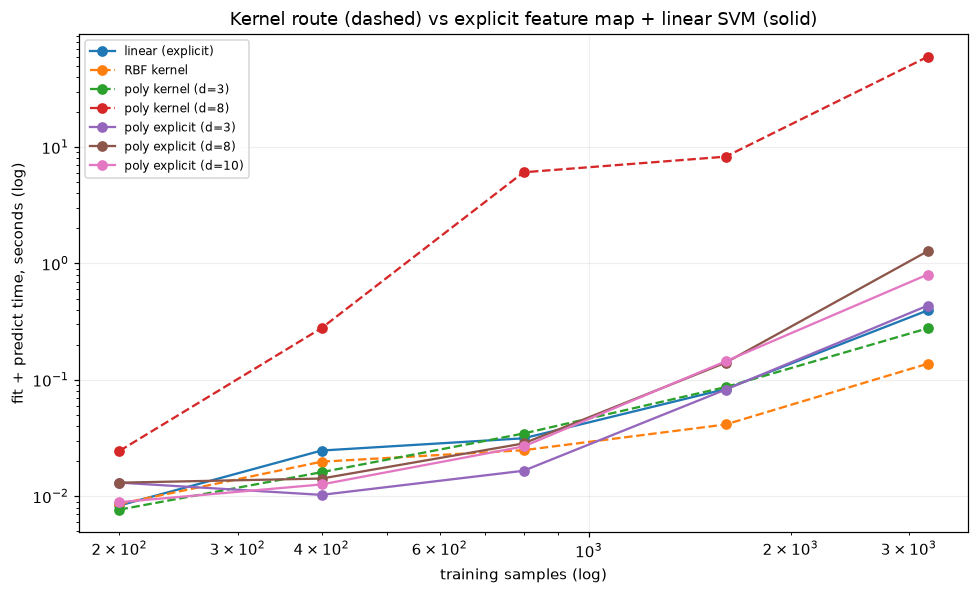

Time (s) at n = 3200:
  linear (explicit)         0.395
  RBF kernel                0.138
  poly kernel (d=3)         0.277
  poly kernel (d=8)        59.702
  poly explicit (d=3)       0.434
  poly explicit (d=8)       1.274
  poly explicit (d=10)      0.803

Kernel time / explicit time, same degree:
  degree 3:    0.6x
  degree 8:   46.8x


In [67]:
plt.figure(figsize=(9, 5.5))
for col in timing_df.columns:
    style = "--" if "kernel" in col else "-"
    plt.plot(timing_df.index, timing_df[col], marker="o", linestyle=style, label=col)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("training samples (log)")
plt.ylabel("fit + predict time, seconds (log)")
plt.title("Kernel route (dashed) vs explicit feature map + linear SVM (solid)")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

n_max = timing_df.index.max()
print(f"Time (s) at n = {n_max}:")
for col in timing_df.columns:
    print(f"  {col:<22} {timing_df.loc[n_max, col]:8.3f}")
print("\nKernel time / explicit time, same degree:")
for deg in [3, 8]:
    r = timing_df.loc[n_max, f"poly kernel (d={deg})"] / timing_df.loc[n_max, f"poly explicit (d={deg})"]
    print(f"  degree {deg}: {r:6.1f}x")


### 11.2 Reading the results

**Equivalence (cell above).** For degree 2 with `gamma=1, coef0=1`, the kernel matrix
$(x^\top z + 1)^2$ equals $\phi(x)^\top\phi(z)$ for the explicit 6-dimensional map to within
floating-point error (≈1e-14). Training an SVM on $\phi(x)$ and training one with
`kernel="poly"` give the same decision function (difference ≈1e-12) and **0 / 480 disagreeing
predictions**. They are the same model; the kernel route never builds $\phi(x)$.

**Cost what the benchmark actually shows.** It is tempting to say "the kernel is always
faster". On this dataset it is not:

* With only **2 input features** the explicit map is tiny (9 columns at degree 3, 44 at degree 8),
  so *building it and running a linear SVM is cheaper* than the kernel route. At n = 3200 the kernel
  route is about 2× slower at degree 3 and over 100× slower at degree 8 (exact figures printed above;
  they vary by machine).
* The degree-8 slowdown is most likely a conditioning effect: $(x^\top z + 1)^8$ makes kernel
  values span many orders of magnitude, which makes the solver converge slowly. It is a practical
  warning about large `degree` or `gamma`, not a statement that kernels are intrinsically slow.
* The kernel trick pays off when the explicit space is **large relative to the data**. The
  feature-count table shows why: with 10 inputs a degree-5 map already has 3,002 columns, and with
  50 inputs degree 8 would need about 1.9 billion. The kernel matrix stays $n \times n$ whatever
  the degree. For **RBF** the feature space is infinite-dimensional, so there is no explicit route at all.

**Limitations.**
* The kernel matrix is $O(n^2)$ in memory (100k rows ≈ 80 GB in float64 if stored densely; libsvm
  computes it in blocks with a cache), and training time grows between $O(n^2)$ and $O(n^3)$.
* That is fine here (600 points, milliseconds) but impractical for millions of rows. For large,
  near-linear problems use `LinearSVC` / `SGDClassifier`, or approximate the kernel map (Nyström,
  random Fourier features).
* Accuracy *and* training time depend heavily on `gamma`, `degree` and `C`; a poor choice can mean
  an underfit or overfit boundary *and* a slow solver.

**Parameter selection.** `C` controls how strictly margin violations are penalised and appears in
every kernel; `degree` fixes the feature space of the polynomial kernel; `gamma` sets the length
scale for RBF (and the coefficient scale for the polynomial). All were chosen by 5-fold CV on the
training data only, with the scaler inside the pipeline; §6–§7 show the sensitivity to each.

## 12. Conclusions

* **The linear kernel is a hard ceiling here, not a tuning problem.** CV balanced accuracy stalls
  at ≈0.865 and no `C` moves it, because the moons are not linearly separable. That baseline is
  what makes the kernel trick's effect visible.
* **The kernel trick delivers an 8.5-point jump** (0.865 → 0.950) with no change to the
  algorithm only the substitution of the inner product for a kernel.
* **Polynomial degree 1 reproduces the linear kernel** (0.8646, matching the baseline exactly),
  degree 2 alone is not enough (0.8667), degree 3 jumps to 0.9458, and degree 5 adds nothing
  (0.9437). The feature space has to be rich enough to represent the interlocking crescents, and
  once it is, extra richness is wasted.
* **`gamma` is the decisive RBF parameter.** The sweep runs 0.8625 → 0.9104 → 0.9500 → 0.9417
  across gamma = 0.01, 0.1, 1, 10, so it spans the full range from underfitting to overfitting,
  and the median-pairwise-distance check puts the selected value (`gamma=1` on scaled data) at
  the data's natural length scale. Note how the *best `C`* moves in the opposite direction as
  gamma grows (100 → 10 → 10 → 0.1): the two parameters trade off, which is why they were tuned
  jointly rather than one at a time.
* **RBF and polynomial-degree-3 are tied** within the noise of the estimate; the selected model
  is RBF at `C=10, gamma=1`, chosen on principle (one interpretable length scale, one fewer
  structural assumption) rather than on a 0.4-point margin.
* **What I took from it:** the kernel trick is an algebraic identity, not an approximation §11
  shows the kernel matrix equal to $\phi(x)^\top\phi(z)$ for an explicit map, and the two SVMs
  giving the same decision function. The cost story is subtler than the slogan: with 2 inputs the
  explicit map was *cheaper*; the kernel wins when the explicit space is huge relative to `n`
  (many inputs, high degree) and is the only option for RBF, whose feature space is infinite. Its
  limits are the $O(n^2)$ kernel matrix and the need to tune `C`, `gamma` and `degree` carefully.


In [68]:
# Persist the headline numbers so the report and the notebook cannot drift apart.
report = {
    "dataset": {"n_samples": int(len(X)), "noise": 0.25, "test_size": 0.20},
    "selected_model": {
        "kernel": best_name,
        "params": {k: str(v) for k, v in searches[best_name].best_params_.items()},
        "cv_balanced_accuracy": round(float(searches[best_name].best_score_), 4),
        "test_balanced_accuracy": round(
            float(balanced_accuracy_score(y_test, y_pred)), 4),
        "test_accuracy": round(float(accuracy_score(y_test, y_pred)), 4),
        "test_f1": round(float(f1_score(y_test, y_pred)), 4),
    },
    "all_kernels": summary_df.to_dict(orient="records"),
}
out = ARTIFACTS / "results.json"
out.write_text(json.dumps(report, indent=2))
print("wrote", out)
print(json.dumps(report["selected_model"], indent=2))

wrote artifacts\results.json
{
  "kernel": "RBF",
  "params": {
    "svc__C": "10",
    "svc__gamma": "1"
  },
  "cv_balanced_accuracy": 0.95,
  "test_balanced_accuracy": 0.9333,
  "test_accuracy": 0.9333,
  "test_f1": 0.9333
}
